# §8 Fairness and the 3 × 3 Label Matrix (Stage S8)

§5 showed that the label and one feature are measured unevenly across groups: self-report misses the 152 people
whose diabetes is undiagnosed, and these people are more often uninsured or without a usual place of care, while BMI
under-reads adiposity in Asian adults. This section checks whether those measurement biases **carry over into the
model**. Three parts follow:

1. **Group audit** – error rates of arm S by race, insurance, access to care, income and sex at one fixed threshold,
   with bootstrap intervals, small-cell suppression and a permutation baseline.
2. **3 × 3 label matrix** (pre-registered H3) – the same pipeline trained on three labels and scored on three kinds
   of diabetes, plus an audit arm that shows how the access-to-care imprint differs between labels.
3. **Mitigation** – reweighing (race, insurance, access), the WHtR measurement fix (P14-b), the fairness–performance
   trade-off and within-group calibration.

All results use the out-of-fold (OOF) predictions of the **training part** and the stored folds of §7. The 20 %
hold-out is not read; its single use belongs to S9 after `exp-freeze`. Race, insurance and access never enter the
prediction model (S1 availability rule): they are audit variables only.

Contents: 0 setup · 1 audit groups · 2 group metrics · 3 gaps and permutation baseline · 4 E-SCREEN · 5 Tier 2 ·
6 3 × 3 label matrix · 7 access-proxy audit · 8 reweighing · 9 WHtR fix · 10 group-specific thresholds ·
11 trade-off · 12 within-group calibration · 13 verdicts · 14 register and storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as SV, fairness as F

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
OUT = C.RESULTS_DIR / "S8"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
N_PERM_GROUP = 200          # group-label permutations (process doc S8 step 2)
SPEC = C.SPEC_FIXED
GAP, GAP_SUB = C.SESOI["group_tpr_gap"], C.SESOI["group_tpr_gap_substantive"]
T_START = time.time()
S8 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm_group": N_PERM_GROUP,
      "spec": SPEC}
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, {N_PERM_GROUP} group permutations, {N_JOBS} workers")

mode FAST: 5x2 CV, B = 100, 200 group permutations, 12 workers


## 0 Setup
**Why.** S8 must evaluate exactly the predictions that §7 judged, on the same rows and folds. The cohort is rebuilt, the
stored hold-out split is re-verified (not evaluated), the stored folds are reloaded with their hash, and the stored OOF
file is checked against those folds. One fold of arm S is refitted to prove that a refit reproduces the stored
predictions, so that the new arms below (other labels, reweighing) are paired with S on identical terms.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X1 = P.raw_feature_frame(raw_tr, 1)
y = cl["L_comb"].to_numpy().astype(int)
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold, n_train_fold = n / C.CV_SPLITS, n - n / C.CV_SPLITS
grp = F.audit_groups(cl)
S7m = R.load_section("S7")
C0 = float(S7m["C0"]["C0"])
assert folds.hash[:16] == S7m["splits"]["folds_hash"][:16] or C.NB_MODE == "FAST"

oof_all = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet")
oof_all = oof_all[oof_all["repeat"] < C.CV_REPEATS]          # FAST folds = first 2 repeats of the FINAL folds
assert not set(oof_all["SEQN"]) & set(clean["SEQN"].iloc[te]) and set(oof_all["SEQN"]) <= set(cl["SEQN"])   # no hold-out row
assert (oof_all.drop_duplicates("row").set_index("row")["SEQN"].sort_index().to_numpy() == cl["SEQN"].to_numpy()).all()
OOF = {}
for (a, t, m), g in oof_all.groupby(["arm", "tier", "model"], observed=True):
    OOF[(a, int(t), m)] = g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)
# every stored (repeat, fold) test set equals the stored fold file
s_oof = OOF[("S", 1, "lr")]
for i, (_, te_i) in enumerate(folds):
    r_, f_ = i // folds.n_splits, i % folds.n_splits
    assert np.array_equal(np.sort(s_oof.query("repeat == @r_ and fold == @f_")["row"].to_numpy()), te_i)
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}            # repeat-averaged OOF probability per row

cfgS = P.ARMS["S"]
fpS = P.fit_params(cfgS, raw_tr)
w_svy = P.survey_weights(raw_tr)
tr0, te0 = folds[0]
m0 = P.build_pipeline(cfgS, 1, C_=C0).fit(X1.iloc[tr0], y[tr0], model__sample_weight=w_svy[tr0])
refit = m0.predict_proba(X1.iloc[te0])[:, 1]
stored = s_oof.query("repeat == 0 and fold == 0").set_index("row").loc[te0, "prob"].to_numpy()
max_dev = float(np.abs(refit - stored).max())
assert max_dev < 1e-5, max_dev
assert np.array_equal(P.training_label(raw_tr, cfgS), y)        # arm S trains on the frozen L_comb
print(f"training part {n:,} rows, {y.sum()} L_comb positives; E-SCREEN {esc.sum():,} rows, {y_esc[esc].sum()} positives")
print(f"folds {folds.n_splits}x{folds.n_repeats}, hash {folds.hash[:16]}...; C0 = {C0}; OOF runs loaded: {len(OOF)}")
print(f"refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = {max_dev:.2e} (float32 storage)")
S8["setup"] = dict(n_train=n, n_pos=int(y.sum()), n_escreen=int(esc.sum()), n_pos_escreen=int(y_esc[esc].sum()),
                   folds_hash=folds.hash, C0=C0, refit_max_abs_diff=max_dev)

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives
folds 5x2, hash eb0f2b5f07f6613b...; C0 = 0.1; OOF runs loaded: 46
refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = 2.97e-08 (float32 storage)


**So what.** The stored predictions belong to the stored folds, and refitting arm S reproduces them to float32
precision. Every new arm in this section is therefore a paired comparison with the S predictions that §7 evaluated.
The training part holds 4,584 adults; the E-SCREEN subset has only about 127 positives.

## 1 Audit groups
**Why.** The audit must be planned around cell sizes. With no race or income oversampling in this cycle, several groups
have only a few dozen cases. Five attributes are audited: race (NH Asian separate and always exploratory),
insurance (HIQ011), **low access** (uninsured *or* no usual place of care, HUQ030 – the two access measures §5 linked
to being undiagnosed), income band (PIR < 1.3 / 1.3–3.49 / ≥ 3.5 / missing) and sex. The reference level is the
largest or most advantaged group. Small-cell rule (NCHS presentation standard): a group with n < 30 or fewer than 30
positives (the TPR denominator) is still shown, but no verdict is drawn on its gap.

**Ecological-fallacy caveat.** Every number below describes a *group* of people scored by the model. A lower TPR for a
group says that the model misses a larger share of that group's cases; it does not say that any individual in it
has a different risk, nor that group membership causes the difference. Group membership is also never used to
score an individual.

In [3]:
def pop_of(name):
    """(label vector, evaluation mask) of an evaluation population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    raise ValueError(name)

size_rows = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy()
        size_rows.append({"attribute": attr, "group": lv, "ref": lv == F.REFERENCE[attr], "n": int(m.sum()),
                          "pos_eall": int(y[m].sum()), "n_escreen": int((m & esc).sum()), "pos_escreen": int(y_esc[m & esc].sum()),
                          "status_eall": F.cell_status(int(m.sum()), int(y[m].sum())),
                          "status_escreen": F.cell_status(int((m & esc).sum()), int(y_esc[m & esc].sum()))})
    size_rows.append({"attribute": attr, "group": "(unknown)", "n": int(grp[attr].isna().sum())})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(OUT / "group_sizes.csv", index=False)
print(sizes.to_string(index=False))
n_supp = {p: int((sizes[f"status_{p}"] == "suppress").sum()) for p in ("eall", "escreen")}
print(f"\nsuppressed groups (n < 30 or positives < 30): E-ALL {n_supp['eall']}, E-SCREEN {n_supp['escreen']} "
      f"of {int(sizes['status_eall'].notna().sum())}")
S8["group_sizes"] = sizes.to_dict("records")
S8["n_suppressed"] = n_supp

 attribute            group   ref    n  pos_eall  n_escreen  pos_escreen status_eall status_escreen
      race         NH White  True 2727     398.0     2392.0         63.0     present        present
      race         NH Black False  540     131.0      433.0         24.0     present       suppress
      race         NH Asian False  252      40.0      223.0         11.0     present       suppress
      race Mexican American False  309      69.0      256.0         16.0     present       suppress
      race   Other Hispanic False  465      82.0      394.0         11.0     present       suppress
      race      Other/Multi False  291      57.0      236.0          2.0     present       suppress
      race        (unknown)   NaN    0       NaN        NaN          NaN         NaN            NaN
 insurance          insured  True 4186     725.0     3571.0        110.0     present        present
 insurance        uninsured False  390      51.0      356.0         17.0     present       suppress


**So what.** On E-ALL every group except one passes the 30-positive rule; NH Asian adults pass with only 40 positives
and stay exploratory. On E-SCREEN almost every group falls below 30 positives, so E-SCREEN gaps are reported as numbers
only: the screening population is too small in this cycle for any group-fairness verdict except the largest groups.
That is itself a governance finding: a fairness audit of the screening use case needs more data than NHANES 2021–23
provides.

## 2 Group metrics at the fixed threshold
**Why.** Equal opportunity (Hardt et al. 2016) asks whether people *with* diabetes are found at the same rate in each
group. One threshold is fixed for everybody: the score that gives specificity 0.80 on all negatives of the population
(no group-specific thresholds, see section 10). For each group the table reports TPR (sensitivity), FPR, selection
rate, PPV, the within-group AUC and the observed-to-expected ratio (O:E = cases / sum of predicted probabilities).
Intervals come from a stratified bootstrap (rows resampled within group × label, B = `config.N_BOOT`) in which the
threshold is **re-estimated in every replicate**, so the threshold's own uncertainty is included. Arm S is
class-weighted (P11), so its probabilities are inflated by design and its O:E is far below 1 everywhere; only
differences in O:E between groups are informative for S (absolute calibration is examined in section 12).

In [4]:
AUD = {}   # (attr, pop, tier, arms) -> (point, boot, codes, mask)

def audit(attr, pop="E-ALL", tier=1, arms=("S",), weights="simple", preds=None):
    """Run the bootstrap engine for one attribute / population / tier and a tuple of arms (paired)."""
    key = (attr, pop, tier, tuple(arms), weights)
    if key in AUD and preds is None:
        return AUD[key]
    yy, m = pop_of(pop)
    lv = F.LEVELS[attr]
    codes = F.encode(grp[attr], lv)[m]
    Pm = np.vstack([(PM[(a, tier, "lr")] if preds is None or a not in preds else preds[a])[m] for a in arms])
    point = F.boot_engine(yy[m], Pm, codes, len(lv))
    seed = ek.derive_seed(C.SEED_MASTER, "S8", attr, pop, tier, weights)
    if weights == "simple":
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", yy[m].astype(str))), C.N_BOOT, seed)
    else:
        W = F.psu_counts(cl.loc[m, [C.STRATA, C.PSU]].reset_index(drop=True), C.N_BOOT, seed)
    boot = F.boot_engine(yy[m], Pm, codes, len(lv), W)
    out = (point, boot, codes, m)
    if preds is None:
        AUD[key] = out
    return out

def tables(pop="E-ALL", tier=1, arm="S"):
    gt, et = [], []
    for attr in F.ATTRIBUTES:
        point, boot, _, _ = audit(attr, pop, tier, (arm,))
        g = F.group_table(point, boot, F.LEVELS[attr], attribute=attr)
        e = F.eod_table(point, boot, F.LEVELS[attr], F.REFERENCE[attr], attribute=attr)
        g.insert(0, "pop", pop); g.insert(1, "tier", tier)
        e.insert(0, "pop", pop); e.insert(1, "tier", tier)
        gt.append(g); et.append(e)
    return pd.concat(gt, ignore_index=True), pd.concat(et, ignore_index=True)

t0 = time.time()
GT1, ET1 = tables("E-ALL", 1)
thr_eall = float(audit("race")[0]["thr"][0, 0])
rec_check, thr_check = ek.recall_at_specificity(y, PM[("S", 1, "lr")])
assert abs(audit("race")[0]["tpr"][0, 0].dot(audit("race")[0]["n_pos"][0, 0]) / y.sum() - rec_check) < 1e-12
show = ["attribute", "group", "n", "n_pos", "tpr", "tpr_lo", "tpr_hi", "fpr", "sel", "ppv", "auc", "auc_lo", "auc_hi", "oe", "status", "flags"]
print(f"E-ALL, Tier 1, arm S: threshold {thr_eall:.4f} (specificity 0.80 on {int((y == 0).sum())} negatives); "
      f"overall TPR {rec_check:.3f}; {time.time() - t0:.1f} s")
print(GT1[show].round(3).to_string(index=False))

E-ALL, Tier 1, arm S: threshold 0.6389 (specificity 0.80 on 3807 negatives); overall TPR 0.663; 0.1 s
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe  status       flags
      race         NH White 2727    398 0.693   0.644   0.744 0.210 0.281 0.360 0.844   0.829   0.855 0.356 present            
      race         NH Black  540    131 0.618   0.538   0.691 0.227 0.322 0.466 0.782   0.745   0.820 0.543 present            
      race         NH Asian  252     40 0.475   0.362   0.650 0.123 0.179 0.422 0.856   0.813   0.904 0.498 present exploratory
      race Mexican American  309     69 0.609   0.514   0.732 0.146 0.249 0.545 0.840   0.787   0.889 0.570 present            
      race   Other Hispanic  465     82 0.744   0.664   0.836 0.175 0.275 0.477 0.869   0.833   0.905 0.437 present            
      race      Other/Multi  291     57 0.632   0.500   0.746 0.214 0.296 0.419 0.834   0.756   0.875 0.462 present            
 i

**So what.** At one shared threshold the model finds about two thirds of all cases, but not evenly. The lowest
TPRs belong to NH Asian adults, the low-access group and the uninsured; the highest to the lowest income band. Low
TPR comes with low FPR and low selection rate in the same groups (NH Asian, low access, uninsured): the whole score
distribution of these groups sits lower, so the single threshold selects fewer of them, cases and non-cases alike.
Within-group AUCs overlap widely (about 0.78–0.87), so the *ranking* inside each group is similar; the gaps arise
from where each group's scores lie relative to the shared threshold. Whether they exceed sampling noise is tested
next.

## 3 Gaps and permutation baseline
**Why.** A gap is only interesting if it is larger than what random group labels would produce. Two checks are
combined: (i) the equal-opportunity difference EOD = TPR_group − TPR_reference with its bootstrap CI, flagged at
|EOD| ≥ 0.05 (SESOI) and called **substantive** only if |EOD| ≥ 0.10 *and* its CI excludes 0; (ii) a group-label
permutation null: group labels are shuffled 200 times (sizes kept, threshold fixed) and the observed max |EOD| over
the reportable groups is compared with the null distribution of that maximum. The maximum is the right statistic
because with six race groups the largest of five gaps is expected to look sizeable even by chance.

In [5]:
def permutation_block(pop="E-ALL", tier=1, arm="S", preds=None):
    rows, nulls = [], {}
    yy, m = pop_of(pop)
    for attr in F.ATTRIBUTES:
        point, boot, codes, mm = audit(attr, pop, tier, (arm,), preds=preds)
        lv = F.LEVELS[attr]
        ref = lv.index(F.REFERENCE[attr])
        ok = [g for g in range(len(lv)) if F.cell_status(int(point["n"][0, 0, g]), int(point["n_pos"][0, 0, g])) == "present"]
        p_ = (PM[(arm, tier, "lr")] if preds is None else preds[arm])[mm]
        thr = np.nextafter(point["thr"][0, 0], np.inf)        # engine: positive if p > v  <=>  p >= nextafter(v)
        if ref not in ok or len(ok) < 2:
            rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - (ref in ok),
                         "observed_max_eod": np.nan, "null_q95": np.nan, "p_value": np.nan, "note": "reference or all groups suppressed"})
            continue
        res = F.eod_permutation(yy[mm], p_, codes, len(lv), ref, thr, eligible=ok, n_perm=N_PERM_GROUP,
                                seed=ek.derive_seed(C.SEED_MASTER, "S8", "perm", attr, pop, tier))
        tp = point["tpr"][0, 0]
        assert abs(res["observed"] - max(abs(tp[g] - tp[ref]) for g in ok if g != ref)) < 1e-12
        nulls[attr] = res["null"]
        rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - 1,
                     "observed_max_eod": res["observed"], "null_mean": res["null_mean"], "null_q95": res["null_q95"],
                     "p_value": res["p_value"], "note": ""})
    return pd.DataFrame(rows), nulls

PERM1, NULL1 = permutation_block("E-ALL", 1)
print("Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):")
print(ET1[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "fpr_diff", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print("\nPermutation null of max |EOD| (reportable groups only):")
print(PERM1.round(3).to_string(index=False))
sub1 = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
print(f"\nsubstantive gaps (|EOD| >= {GAP_SUB}, CI excludes 0, reportable): {len(sub1)} -> "
      f"{sub1[['attribute', 'group', 'eod']].round(3).to_dict('records')}")

Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):
 attribute            group          ref    eod  eod_lo  eod_hi  fpr_diff  flag_0.05  substantive verdict_status
      race         NH Black     NH White -0.075  -0.171   0.013     0.017       True        False     reportable
      race         NH Asian     NH White -0.218  -0.352  -0.080    -0.088       True         True     reportable
      race Mexican American     NH White -0.085  -0.193   0.037    -0.065       True        False     reportable
      race   Other Hispanic     NH White  0.050  -0.043   0.155    -0.035       True        False     reportable
      race      Other/Multi     NH White -0.062  -0.190   0.068     0.003       True        False     reportable
 insurance        uninsured      insured -0.058  -0.170   0.064    -0.081       True        False     reportable
low_access       low access usual access -0.084  -0.199   0.031    -0.121       True        False     reportable
    income     PIR 1.3

**So what.** Two attributes carry gaps that survive both checks: **race**, driven by NH Asian adults (exploratory,
40 positives), and **income**, where the *lower* income bands are found *more* often than the highest band. Their
largest gaps exceed the 95th percentile of the permutation null. Insurance and sex show nothing beyond chance on
E-ALL; the low-access gap sits at the edge of the null. The next table asks *why* these groups differ, because race,
insurance and access are not model inputs: a gap must travel through correlated features.

### Where the gaps come from
**Why.** On E-ALL, 84 % of positives already know their diagnosis and carry care traces (told hypertension or high
cholesterol, BPQ020/BPQ080), which raise the score. If a group's cases are less often diagnosed, or are younger or
leaner, the shared threshold will miss more of them. The table describes the positives of each group: share
diagnosed, mean age, mean BMI, and the TPR separately for diagnosed and undiagnosed cases.

In [6]:
pS = PM[("S", 1, "lr")]
hitS = pS >= thr_check
dec = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy() & (y == 1)
        dx = m & (cl["L_self"].to_numpy() == 1)
        ud = m & (cl["L_self"].to_numpy() == 0)
        dec.append({"attribute": attr, "group": lv, "n_pos": int(m.sum()), "share_diagnosed": dx.sum() / m.sum(),
                    "mean_age": cl.loc[m, "RIDAGEYR"].mean(), "mean_bmi": cl.loc[m, "BMXBMI"].mean(),
                    "care_trace": (cl.loc[m, "BPQ020"].eq(1) | cl.loc[m, "BPQ080"].eq(1)).mean(),
                    "tpr": hitS[m].mean(), "tpr_diagnosed": hitS[dx].mean(), "tpr_undiagnosed": hitS[ud].mean() if ud.sum() else np.nan})
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT / "gap_decomposition.csv", index=False)
print(DEC.round(3).to_string(index=False))
r_dx = float(np.corrcoef(DEC["share_diagnosed"], DEC["tpr"])[0, 1])
r_age = float(np.corrcoef(DEC["mean_age"], DEC["tpr"])[0, 1])
r_care = float(np.corrcoef(DEC["care_trace"], DEC["tpr"])[0, 1])
tpr_dx_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 1)].mean()
tpr_ud_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 0)].mean()
print(f"\nall positives: TPR diagnosed {tpr_dx_all:.3f} vs undiagnosed {tpr_ud_all:.3f}")
print(f"across the 16 groups, correlation of TPR with share diagnosed {r_dx:.2f}, with care-trace share {r_care:.2f}, "
      f"with mean age {r_age:.2f}")
S8["gap_decomposition"] = dict(table=DEC.round(4).to_dict("records"), tpr_diagnosed=tpr_dx_all, tpr_undiagnosed=tpr_ud_all,
                               r_tpr_share_diagnosed=r_dx, r_tpr_care_trace=r_care, r_tpr_mean_age=r_age)

 attribute            group  n_pos  share_diagnosed  mean_age  mean_bmi  care_trace   tpr  tpr_diagnosed  tpr_undiagnosed
      race         NH White    398            0.842    64.455    34.031       0.897 0.693          0.701            0.651
      race         NH Black    131            0.817    58.405    34.682       0.802 0.618          0.692            0.292
      race         NH Asian     40            0.725    64.550    26.441       0.800 0.475          0.552            0.273
      race Mexican American     69            0.768    59.087    32.419       0.754 0.609          0.679            0.375
      race   Other Hispanic     82            0.866    62.293    31.742       0.927 0.744          0.775            0.545
      race      Other/Multi     57            0.965    62.649    33.933       0.877 0.632          0.636            0.500
 insurance          insured    725            0.848    63.301    33.318       0.877 0.666          0.693            0.518
 insurance        uninsu

**So what.** Three different routes produce the gaps:

* **Diagnosis and care traces (label route).** The model finds diagnosed cases far more often than undiagnosed ones
  (TPRs printed above), and a group's TPR rises with the share of its cases that are already diagnosed and carry care
  traces (correlations printed above). Uninsured and low-access cases are less often diagnosed, younger and have fewer
  care traces – the access imprint on the label documented in §5, reproduced by the model.
* **Body-size measurement (feature route).** NH Asian cases are as old as White cases and as often diagnosed, but much
  leaner (mean BMI about 26 against 34). BMI – the measurement §5 found biased for Asian adults – pushes their scores
  down, so they are missed even when diagnosed.
* **Socio-economic risk markers (direct route).** Income (INDFMPIR) and education are model inputs with negative
  coefficients, so the model scores low-income people higher; the highest income band is missed most although its
  cases are as often diagnosed and as old as the others. This is the model using SES as a risk marker – a gap it was
  built to have, not a measurement artefact.

The race and access gaps are therefore mostly **label and measurement bias transmitted through the features**,
not a separate model defect – which means a model-side fix (reweighing) is unlikely to remove them, while a
measurement fix (WHtR) targets one of the routes directly. Both are tested in sections 8–9.

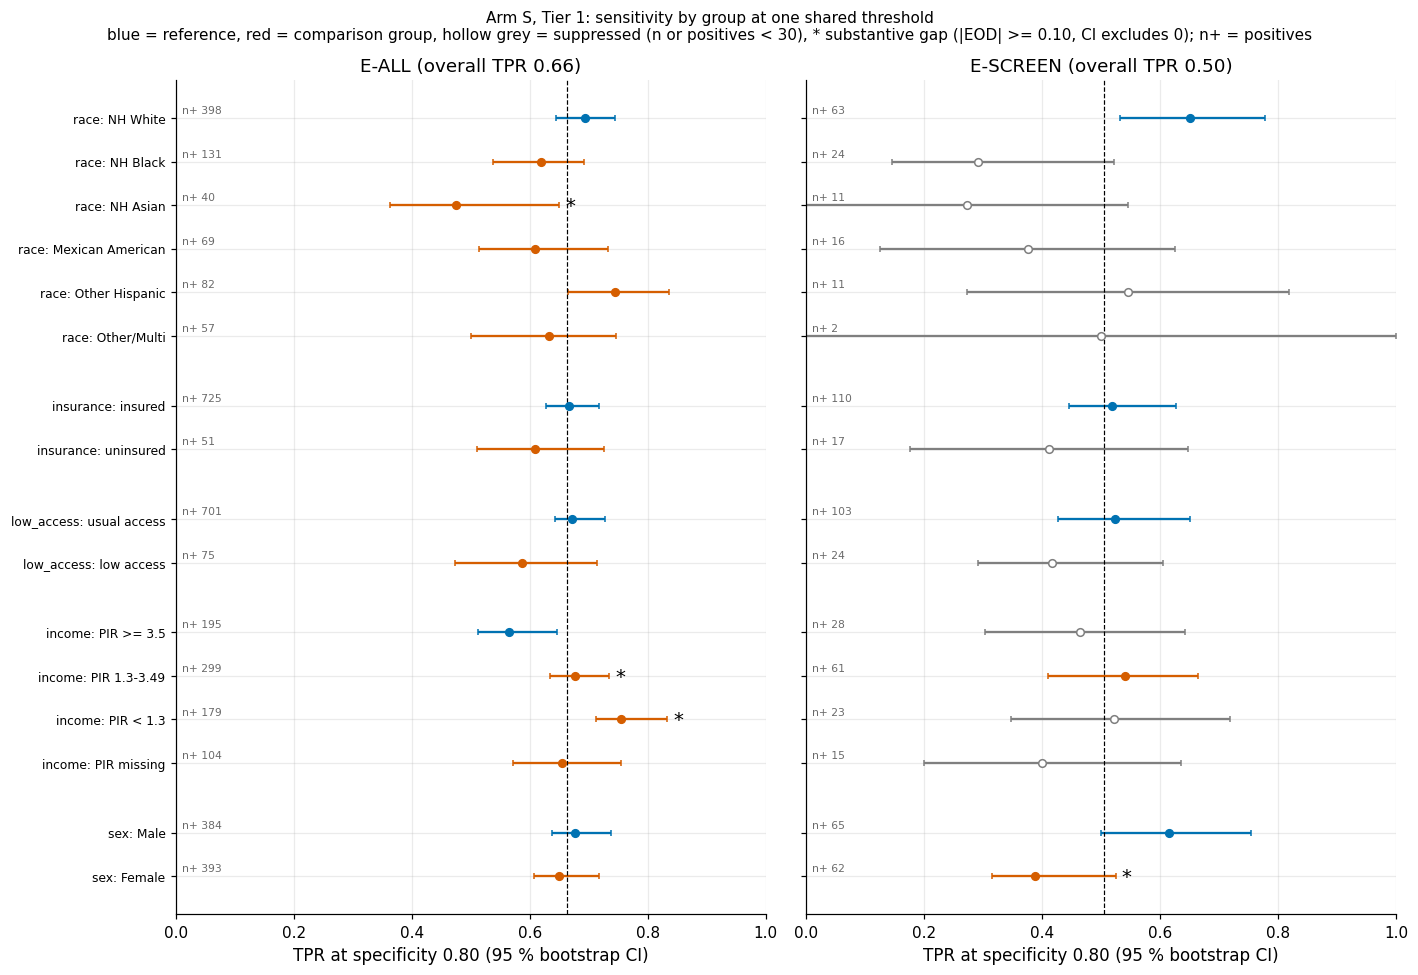

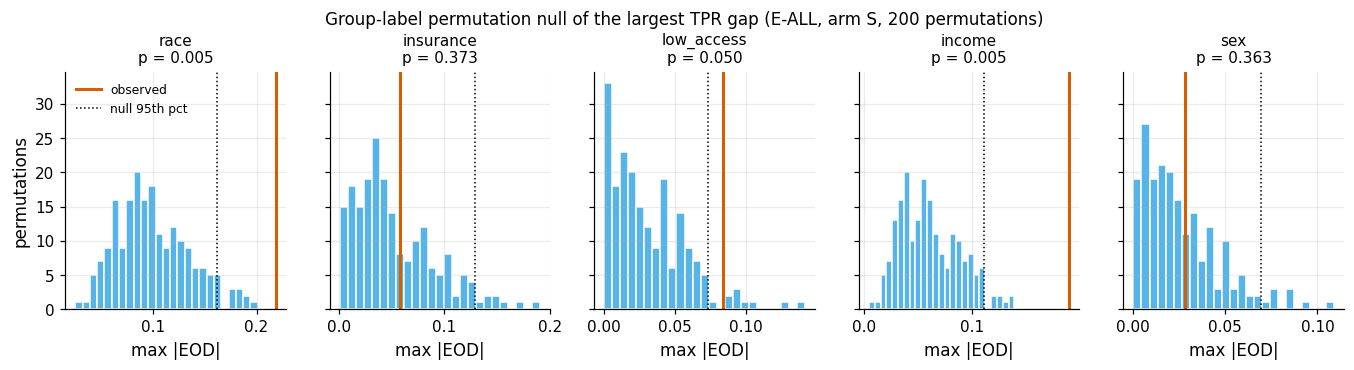

In [7]:
plots.set_style()
def tpr_panel(ax, GT, ET, title, overall):
    """Point-range of group TPRs; returns y labels (attribute: group)."""
    ylabels, ypos, k = [], [], 0
    for attr in F.ATTRIBUTES:
        g = GT[GT["attribute"] == attr]
        for _, r in g.iterrows():
            sup = r["status"] == "suppress"
            col = C.OKABE_ITO["grey"] if sup else (C.OKABE_ITO["blue"] if r["group"] == F.REFERENCE[attr] else C.OKABE_ITO["vermillion"])
            ax.errorbar(r["tpr"], -k, xerr=[[r["tpr"] - r["tpr_lo"]], [r["tpr_hi"] - r["tpr"]]], fmt="o",
                        color=col, mfc="white" if sup else col, capsize=2, ms=5)
            e = ET[(ET["attribute"] == attr) & (ET["group"] == r["group"])]
            if len(e) and bool(e["substantive"].iloc[0]) and e["verdict_status"].iloc[0] == "reportable":
                ax.annotate("*", (r["tpr_hi"], -k), xytext=(4, -4), textcoords="offset points", fontsize=13, color="black")
            ax.annotate(f"n+ {int(r['n_pos'])}", (0.01, -k), xytext=(0, 3), textcoords="offset points", fontsize=7, color="dimgrey")
            ylabels.append(f"{attr}: {r['group']}")
            ypos.append(-k)
            k += 1
        k += 0.6
    ax.axvline(overall, color="black", lw=0.8, ls="--")
    ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlabel("TPR at specificity 0.80 (95 % bootstrap CI)")
    ax.set_title(title)
    ax.set_xlim(0, 1)

# E-SCREEN tables are needed for the right panel (computed in section 4, re-used there)
GTs, ETs = tables("E-SCREEN", 1)
rec_s, _ = ek.recall_at_specificity(y_esc[esc], PM[("S", 1, "lr")][esc])
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
tpr_panel(axes[1], GTs, ETs, f"E-SCREEN (overall TPR {rec_s:.2f})", rec_s)
axes[1].tick_params(labelleft=False)
tpr_panel(axes[0], GT1, ET1, f"E-ALL (overall TPR {rec_check:.2f})", rec_check)
fig.suptitle("Arm S, Tier 1: sensitivity by group at one shared threshold\n"
             "blue = reference, red = comparison group, hollow grey = suppressed (n or positives < 30), * substantive gap (|EOD| >= 0.10, CI excludes 0); n+ = positives", fontsize=10)
fig.tight_layout()
f81 = plots.savefig(fig, "S8_group_tpr", caption="F8-1. TPR at specificity 0.80 by audit group for arm S (Tier 1) on E-ALL "
                    "and E-SCREEN, stratified bootstrap 95 % CI with the threshold re-estimated per replicate; dashed line = "
                    "overall TPR; hollow grey markers are suppressed cells (n < 30 or fewer than 30 positives).")
plt.show()

fig, axes = plt.subplots(1, len(F.ATTRIBUTES), figsize=(15, 2.8), sharey=True)
for ax, attr in zip(axes, F.ATTRIBUTES):
    row = PERM1.set_index("attribute").loc[attr]
    if attr in NULL1:
        ax.hist(NULL1[attr], bins=25, color=C.OKABE_ITO["sky"], edgecolor="white")
        ax.axvline(row["observed_max_eod"], color=C.OKABE_ITO["vermillion"], lw=2, label="observed")
        ax.axvline(row["null_q95"], color="black", ls=":", lw=1, label="null 95th pct")
        ax.set_title(f"{attr}\np = {row['p_value']:.3f}", fontsize=10)
    ax.set_xlabel("max |EOD|")
axes[0].set_ylabel("permutations"); axes[0].legend(fontsize=8)
fig.suptitle("Group-label permutation null of the largest TPR gap (E-ALL, arm S, 200 permutations)", fontsize=11, y=1.08)
f81b = plots.savefig(fig, "S8_permutation_null", caption="F8-1b. Null distribution of max |TPR_g - TPR_ref| over the reportable "
                     "groups when group labels are permuted 200 times (threshold fixed), with the observed value (red) "
                     "and the null 95th percentile (dotted). E-ALL, arm S, Tier 1.")
plt.show()
S8["group_metrics_eall_t1"] = GT1.round(5).to_dict("records")
S8["eod_eall_t1"] = ET1.round(5).to_dict("records")
S8["permutation_eall_t1"] = PERM1.round(5).to_dict("records")
S8["threshold_eall_t1"] = thr_eall
S8["overall_tpr_eall_t1"] = rec_check

**So what.** The left panel is the audit in one picture: the reference groups (blue) sit near the overall TPR, and the
comparison groups that deviate are those whose age structure differs. The permutation panel shows, per attribute,
whether the largest gap is beyond chance. A red line far to the right of the blue null means the attribute's largest
gap is real; a red line inside the null means the visible spread is what random grouping of the same people would
produce.

## 4 E-SCREEN
**Why.** E-SCREEN is the population the use case is about (adults not known to have diabetes). The same metrics are
computed with the threshold fixed at specificity 0.80 on the E-SCREEN negatives. With about 127 positives in total,
most groups have fewer than 30 positives; they are reported but receive no verdict.

In [8]:
PERMs, NULLs = permutation_block("E-SCREEN", 1)
print(f"E-SCREEN, Tier 1, arm S: overall TPR {rec_s:.3f}")
print(GTs[show].round(3).to_string(index=False))
print()
print(ETs[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print()
print(PERMs.round(3).to_string(index=False))
rep_s = ETs[ETs["verdict_status"].eq("reportable")]
print(f"\nreportable E-SCREEN gaps: {len(rep_s)} of {len(ETs)}; substantive among them: {int(rep_s['substantive'].sum())}")
S8["group_metrics_escreen_t1"] = GTs.round(5).to_dict("records")
S8["eod_escreen_t1"] = ETs.round(5).to_dict("records")
S8["permutation_escreen_t1"] = PERMs.round(5).to_dict("records")
S8["overall_tpr_escreen_t1"] = rec_s

E-SCREEN, Tier 1, arm S: overall TPR 0.504
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe   status                               flags
      race         NH White 2392     63 0.651   0.531   0.778 0.210 0.222 0.077 0.829   0.784   0.867 0.072  present                                    
      race         NH Black  433     24 0.292   0.145   0.522 0.227 0.231 0.070 0.643   0.576   0.719 0.145 suppress             n_pos<30;ci_width>=0.30
      race         NH Asian  223     11 0.273   0.000   0.545 0.123 0.130 0.103 0.806   0.713   0.892 0.179 suppress n_pos<30;ci_width>=0.30;exploratory
      race Mexican American  256     16 0.375   0.125   0.625 0.146 0.160 0.146 0.765   0.665   0.843 0.193 suppress             n_pos<30;ci_width>=0.30
      race   Other Hispanic  394     11 0.545   0.273   0.818 0.175 0.185 0.082 0.826   0.756   0.898 0.082 suppress             n_pos<30;ci_width>=0.30
      race      Other/Multi  236      2

**So what.** In the screening population only the sex contrast has two groups with 30 or more positives, and it shows
the one reportable screening gap: undiagnosed **women are found less often than undiagnosed men** (EOD and permutation p
printed above). A plausible route is body shape: the model rewards waist and penalises hip circumference, and women
have larger hips at the same waist. The race gaps look larger than on E-ALL (NH Black and NH Asian undiagnosed cases
are found far less often than White ones) but rest on 11–24 positives per group with CIs wider than 0.30, so they are
suppressed: a screening-population race audit is not possible with NHANES 2021–23. "Not reportable" here means
"not measurable", not "fair".

## 5 Tier 2 summary
**Why.** Tier 2 adds total and HDL cholesterol. If lipids carry group-specific information, the gaps could change. The
same audit is repeated on E-ALL and summarised by the largest reportable gap per attribute.

In [9]:
GT2, ET2 = tables("E-ALL", 2)
PERM2, _ = permutation_block("E-ALL", 2)
cmp_t = (ET1.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi", "verdict_status"]]
         .join(ET2.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi"]], rsuffix="_t2"))
cmp_t["delta_t2_t1"] = cmp_t["eod_t2"] - cmp_t["eod"]
print(cmp_t.round(3).to_string())
summ = PERM1.set_index("attribute")[["observed_max_eod", "p_value"]].join(
    PERM2.set_index("attribute")[["observed_max_eod", "p_value"]], rsuffix="_t2")
print("\nmax |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:")
print(summ.round(3).to_string())
max_shift = float(cmp_t["delta_t2_t1"].abs().max())
print(f"largest change of any EOD from Tier 1 to Tier 2: {max_shift:.3f}")
S8["tier2_summary"] = dict(eod=ET2.round(5).to_dict("records"), permutation=PERM2.round(5).to_dict("records"),
                           max_abs_eod_shift=max_shift)

                               eod  eod_lo  eod_hi verdict_status  eod_t2  eod_lo_t2  eod_hi_t2  delta_t2_t1
attribute  group                                                                                            
race       NH Black         -0.075  -0.171   0.013     reportable  -0.082     -0.163      0.020       -0.007
           NH Asian         -0.218  -0.352  -0.080     reportable  -0.164     -0.294      0.009        0.055
           Mexican American -0.085  -0.193   0.037     reportable  -0.101     -0.218      0.036       -0.016
           Other Hispanic    0.050  -0.043   0.155     reportable   0.030     -0.054      0.149       -0.021
           Other/Multi      -0.062  -0.190   0.068     reportable   0.016     -0.103      0.136        0.078
insurance  uninsured        -0.058  -0.170   0.064     reportable  -0.069     -0.192      0.072       -0.010
low_access low access       -0.084  -0.199   0.031     reportable  -0.123     -0.243     -0.009       -0.039
income     PIR 1.3-

**So what.** Adding lipids moves individual gaps by less than their own CIs (the largest shift is printed above); the
same groups stay on the same side of the reference. The attribute-level permutation p-values move around 0.05 for
race, income and low access between tiers, so the *ranking* of which attribute is "significant" is fragile, while
the direction of the gaps is not. Tier 1 remains the primary audit.

## 14 Storage
**Why.** Every number of this section is stored in `results/metrics_S8.json` (via `results_io`) and the tables in
`results/S8/`, so that S10 and the slides read them instead of re-typing them.

In [10]:
for nm, df_ in {"group_metrics_eall_t1": GT1, "eod_eall_t1": ET1, "group_metrics_escreen_t1": GTs, "eod_escreen_t1": ETs,
                "group_metrics_eall_t2": GT2, "eod_eall_t2": ET2,
                "permutation": pd.concat([PERM1, PERMs, PERM2], ignore_index=True)}.items():
    df_.to_csv(OUT / f"{nm}.csv", index=False)
S8["runtime_seconds"] = time.time() - T_START
R.save_section("S8", S8)
print(f"saved results/metrics_S8.json and {len(list(OUT.glob('*.csv')))} tables in results/S8; runtime {S8['runtime_seconds']:.0f} s ({C.NB_MODE})")

saved results/metrics_S8.json and 9 tables in results/S8; runtime 2 s (FAST)
